# Clase 12: Geoespacial con GeoPandas — UT4
**Marcos Devincenzi — Ingeniería de Datos, UCU**

[Consigna](https://juanfkurucz.com/ucu-id/ut4/12-geoespacial/).

Se resuelven carga y validación, partes A–D, nearest, reflexiones finales y **los cinco extras**: hexágonos, accesibilidad por red, overlays, mapa avanzado e IO/performance.

Se conservan los datos de referencia de la consigna. Los contactos SUACI son de **2013–2015** y las capas de población/SUBTE son una fotografía histórica de la fuente, no un inventario certificado de 2026. Los extras incorporan un extracto actual de OpenStreetMap: la comparación mezcla fechas y se interpreta como ejercicio metodológico, no como diagnóstico actualizado de movilidad.

El CRS de análisis es **UTM 21S, EPSG:32721**. EPSG:4326 se usa para intercambio y Folium; EPSG:3857, para el mapa base. El estudio de red se acota a Villa Riachuelo, Villa Lugano, Mataderos y el entorno de estaciones cercanas; los demás análisis abarcan los 48 barrios.

## Setup y carga de datos
### Instalación rápida
Si faltan dependencias, ejecutar la línea siguiente en una celda: `%pip install geopandas shapely pyproj contextily folium mapclassify osmnx pyarrow scipy`. Se incluye `requirements.txt` con las versiones utilizadas. Los datos y la red ya están incluidos: los cálculos no requieren credenciales ni consultas a Overpass.

In [1]:
from pathlib import Path
import json, io, time, platform, html, unicodedata, hashlib
from importlib.metadata import version
import numpy as np
import pandas as pd
import geopandas as gpd
import shapely
from shapely.geometry import Polygon, Point, LineString
import matplotlib.pyplot as plt
import contextily as cx
import mapclassify
import folium
import osmnx as ox
import networkx as nx
from scipy.stats import spearmanr
from sklearn.preprocessing import MinMaxScaler

SEED=42
np.random.seed(SEED)
CRS_METRICO='EPSG:32721'
DATA=Path('data'); OUT=Path('outputs')
for folder in ['tables','maps','layers','figures']:
    (OUT/folder).mkdir(parents=True,exist_ok=True)
plt.rcParams.update({'figure.dpi':105,'font.size':10})
print('Python:',platform.python_version(),'| GeoPandas:',gpd.__version__,'| Shapely:',shapely.__version__)

Python: 3.12.10 | GeoPandas: 1.2.0 | Shapely: 2.2.0


## 1) Leer polígonos de radios censales de CABA
Fuente: [CABA_rc.geojson](https://bitsandbricks.github.io/data/CABA_rc.geojson). Se carga la copia local exacta y se controla CRS, nulidad, vacíos, validez, tipos, identificadores y población. No se asigna un CRS nuevo con `set_crs` para fingir una reproyección.

In [2]:
radios=gpd.read_file(DATA/'CABA_rc.geojson')
assert radios.crs is not None
assert radios.RADIO_ID.is_unique
assert not radios.geometry.isna().any() and not radios.geometry.is_empty.any()
invalidas_entrada=int((~radios.is_valid).sum())
if invalidas_entrada:
    radios.geometry=radios.geometry.make_valid()
assert radios.is_valid.all()
assert radios.geom_type.isin(['Polygon','MultiPolygon']).all()
assert radios.POBLACION.notna().all() and radios.POBLACION.ge(0).all()
print('CRS:',radios.crs,'| filas:',len(radios),'| inválidas de entrada:',invalidas_entrada)
print('Vacías:',radios.is_empty.sum(),'| nulas:',radios.geometry.isna().sum(),'| barrios:',radios.BARRIO.nunique())
radios.head()

CRS: EPSG:4326 | filas: 3554 | inválidas de entrada: 0
Vacías: 0 | nulas: 0 | barrios: 48


,RADIO_ID,BARRIO,COMUNA,POBLACION,VIVIENDAS,HOGARES,HOGARES_NBI,AREA_KM2,geometry
0,1_1_1,RETIRO,1,336.0,82.0,65.0,19.0,1.798997,"MULTIPOLYGON (((-58.37189 -34.59199, -58.37202..."
1,1_12_1,SAN NICOLAS,1,341.0,365.0,116.0,25.0,0.018565,"MULTIPOLYGON (((-58.38593 -34.60444, -58.38575..."
2,1_12_10,SAN NICOLAS,1,296.0,629.0,101.0,1.0,0.044380,"MULTIPOLYGON (((-58.37879 -34.60528, -58.37741..."
3,1_12_11,SAN NICOLAS,1,528.0,375.0,136.0,7.0,0.366340,"MULTIPOLYGON (((-58.36733 -34.60562, -58.36713..."
4,1_12_2,SAN NICOLAS,1,229.0,445.0,129.0,16.0,0.018363,"MULTIPOLYGON (((-58.38454 -34.60436, -58.38311..."


## 2) Estándar de CRS y áreas
Se elige UTM 21S porque CABA está en esa zona. Las áreas quedan en m² y las distancias en metros. Web Mercator es útil para tiles, pero su distorsión de superficie no lo hace la primera opción para densidades. La columna `AREA_KM2` de origen se conserva como referencia; el denominador analítico se calcula desde la geometría reproyectada.

In [3]:
radios_m=radios.to_crs(CRS_METRICO)
radios_m['area_m2']=radios_m.area
assert radios_m.area_m2.gt(0).all()
radios_m['densidad_hab_km2']=radios_m.POBLACION/(radios_m.area_m2/1e6)
area_3857=radios.to_crs(3857).area
factor_mercator=float(area_3857.sum()/radios_m.area_m2.sum())
ciudad=radios_m.geometry.union_all()
solape_relativo=1-ciudad.area/radios_m.area_m2.sum()
assert solape_relativo<1e-4
print('Área total UTM (km²):',radios_m.area_m2.sum()/1e6)
print('Factor área 3857 / UTM:',round(factor_mercator,4))
print('Solape relativo suma/union:',solape_relativo)
radios_m[['BARRIO','POBLACION','AREA_KM2','area_m2','densidad_hab_km2']].head()

Área total UTM (km²): 203.74872233749724
Factor área 3857 / UTM: 1.4805
Solape relativo suma/union: 2.874930300378331e-06


,BARRIO,POBLACION,AREA_KM2,area_m2,densidad_hab_km2
0,RETIRO,336.0,1.798997,1.798256e+06,186.847681
1,SAN NICOLAS,341.0,0.018565,1.855722e+04,18375.595450
2,SAN NICOLAS,296.0,0.044380,4.436219e+04,6672.349406
3,SAN NICOLAS,528.0,0.366340,3.661898e+05,1441.875356
4,SAN NICOLAS,229.0,0.018363,1.835561e+04,12475.752851


## Parte A — Visualización básica y normalizaciones
### A.1 Silueta y coropleta rápida
Se compara cuantiles de cinco clases con cortes naturales. Cuantiles reparte observaciones, no población ni superficie, en clases de tamaño parecido; los intervalos pueden tener anchos muy diferentes.

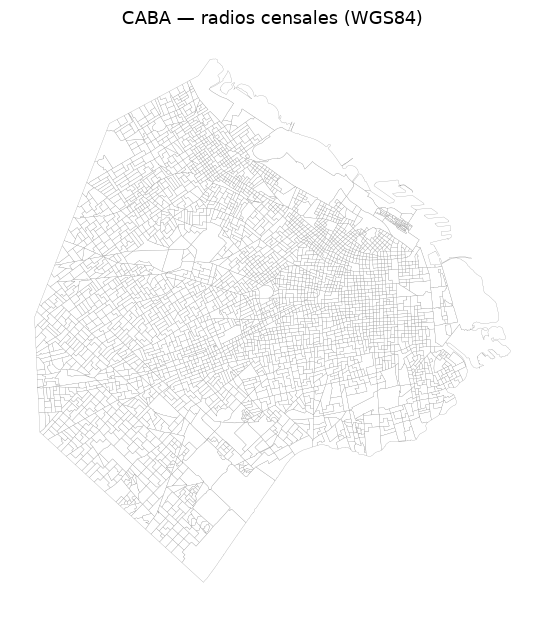

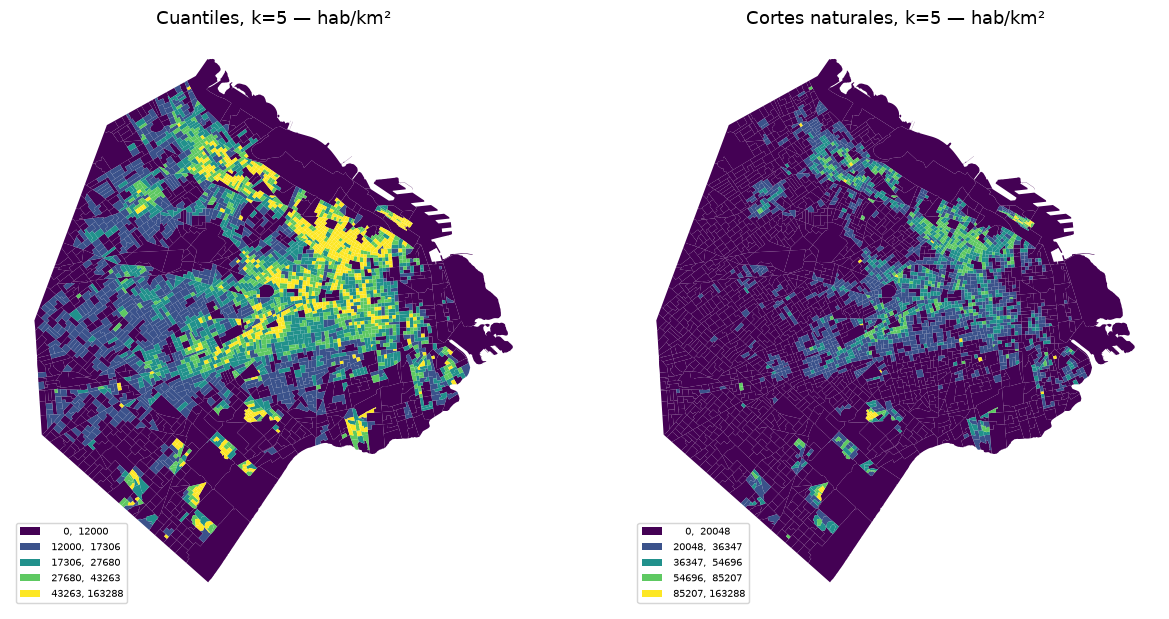

,clase,limite_superior_quantiles,limite_superior_natural
0,1,12000.3,19613.7
1,2,17305.7,35497.5
2,3,27679.8,53746.3
3,4,43263.3,85207.2
4,5,163287.8,163287.8


In [4]:
ax=radios.plot(figsize=(6,6),edgecolor='gray',facecolor='white',linewidth=.15)
ax.set_title('CABA — radios censales (WGS84)'); ax.set_axis_off(); plt.tight_layout(); plt.show()
fig,axes=plt.subplots(1,2,figsize=(12,6))
for ax,scheme,title in zip(axes,['quantiles','natural_breaks'],['Cuantiles, k=5','Cortes naturales, k=5']):
    radios_m.plot(ax=ax,column='densidad_hab_km2',scheme=scheme,k=5,legend=True,cmap='viridis',linewidth=0,
                  legend_kwds={'loc':'lower left','fontsize':7,'fmt':'{:.0f}'})
    ax.set_axis_off(); ax.set_title(title+' — hab/km²')
plt.tight_layout(); plt.show()
clasificaciones=pd.DataFrame({'clase':range(1,6),
    'limite_superior_quantiles':mapclassify.Quantiles(radios_m.densidad_hab_km2,k=5).bins,
    'limite_superior_natural':mapclassify.NaturalBreaks(radios_m.densidad_hab_km2,k=5).bins})
clasificaciones.to_csv(OUT/'tables/clasificaciones_densidad.csv',index=False)
clasificaciones.round(1)

### A.2 Tiles de contexto
Se usa CartoDB.PositronNoLabels y se incluye un GeoTIFF del mapa base para repetir esta figura sin descargar tiles. Atribución: © OpenStreetMap contributors, © CARTO. La reproyección a 3857 se limita a esta visualización.

   BARRIO  densidad_hab_km2
  ALMAGRO           32529.7
BALVANERA           32005.8


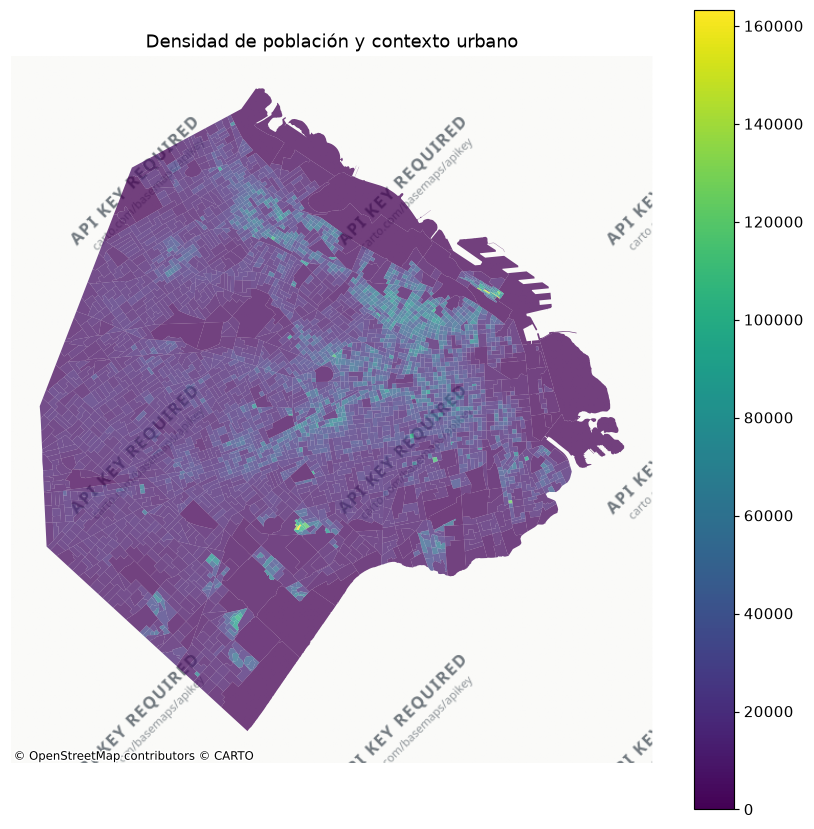

In [5]:
fig,ax=plt.subplots(figsize=(8,8))
radios_m.to_crs(3857).plot(ax=ax,column='densidad_hab_km2',cmap='viridis',legend=True,linewidth=0,alpha=.75)
cx.add_basemap(ax,source=str(DATA/'base_cartodb_3857.tif'),attribution='© OpenStreetMap contributors © CARTO')
ax.set_axis_off(); ax.set_title('Densidad de población y contexto urbano')
plt.tight_layout(); plt.show()
agregado_densidad=radios_m.dissolve('BARRIO',aggfunc={'POBLACION':'sum','area_m2':'sum'}).reset_index()
agregado_densidad['densidad_hab_km2']=agregado_densidad.POBLACION/(agregado_densidad.area_m2/1e6)
top_densidad=agregado_densidad.nlargest(2,'densidad_hab_km2')
print(top_densidad[['BARRIO','densidad_hab_km2']].round(1).to_string(index=False))

### Preguntas de reflexión — Parte A
1. Para comparar el tejido residencial, **quantiles, k=5**, deja visibles diferencias en muchos radios sin concentrar casi todo en una clase. Los cortes naturales sirven mejor para separar valores extremos. Ninguno es universalmente superior; se exportan sus cortes para que los colores no oculten cómo se clasificó.
2. Se normalizó `POBLACION / (area_m2 / 1e6)`: el área calculada está en **m²**, el divisor en **km²** y el resultado en **habitantes/km²**. En estas capas, calcular área en 3857 da un factor 1.481 respecto de UTM: elegir un CRS métrico no elimina automáticamente toda distorsión.
3. Por densidad agregada de barrio, las dos primeras zonas son **ALMAGRO (32,530 hab/km²)** y **BALVANERA (32,006 hab/km²)**. La concentración de viviendas y edificios multifamiliares es una hipótesis plausible; requiere información de edificación para confirmarla. El ranking usa población total / área total, no el promedio simple de densidades de radios.

## Parte B — Attribute join y métricas per cápita
Fuente: [SUACI por comuna/barrio](https://bitsandbricks.github.io/data/gcba_suaci_comunas.csv). Se usa Latin-1 según la consigna. El archivo mezcla texto con mojibake: se repara el texto afectado (por ejemplo, NUÑEZ) antes de normalizar la clave. Las etiquetas de error y vacías se auditan; no se inventa un barrio ni se reparte su total arbitrariamente.

In [6]:
suaci=pd.read_csv(DATA/'gcba_suaci_comunas.csv',encoding='ISO-8859-1')
def reparar_texto(value):
    text=str(value).strip()
    if 'Ã' in text or 'Â' in text:
        try: text=text.encode('latin1').decode('utf-8')
        except (UnicodeEncodeError,UnicodeDecodeError): pass
    return text
def clave_barrio(value):
    text=reparar_texto(value).upper()
    text=''.join(c for c in unicodedata.normalize('NFKD',text) if not unicodedata.combining(c))
    return ' '.join(text.split())
suaci['BARRIO_ORIGINAL']=suaci.BARRIO
suaci['clave']=suaci.BARRIO.map(clave_barrio)
radios_m['clave']=radios_m.BARRIO.map(clave_barrio)
assert suaci.total.ge(0).all() and suaci.total.notna().all()
claves_validas=set(radios_m.clave)
sin_barrio=suaci.loc[~suaci.clave.isin(claves_validas)].copy()
suaci_valido=suaci.loc[suaci.clave.isin(claves_validas)].copy()
sin_barrio.to_csv(OUT/'tables/suaci_sin_barrio_valido.csv',index=False)
print('Períodos SUACI:',suaci.PERIODO.min(),'a',suaci.PERIODO.max())
print('Filas:',len(suaci),'| filas sin barrio:',len(sin_barrio),'| contactos sin barrio:',int(sin_barrio.total.sum()))
print('Casos de clave corregida:',suaci.loc[suaci.BARRIO_ORIGINAL.str.contains('NU',case=False),['BARRIO_ORIGINAL','clave']].drop_duplicates().to_dict('records'))
print('Faltantes COMUNA:',suaci.COMUNA.isna().sum(),'; no se usa COMUNA como clave del join.')
suaci_barrio=suaci_valido.groupby('clave',as_index=False).total.sum()
barrios_m=radios_m.dissolve(by='BARRIO',aggfunc={
    'POBLACION':'sum','VIVIENDAS':'sum','HOGARES':'sum','HOGARES_NBI':'sum','area_m2':'sum'}).reset_index()
barrios_m['clave']=barrios_m.BARRIO.map(clave_barrio)
assert barrios_m.clave.is_unique and suaci_barrio.clave.is_unique
barrios_m=barrios_m.merge(suaci_barrio,on='clave',how='left',validate='one_to_one',indicator=True)
assert barrios_m._merge.eq('both').all()
barrios_m=barrios_m.drop(columns='_merge')
barrios_m['contactos_pc']=barrios_m.total/barrios_m.POBLACION
barrios_m['contactos_1k']=1000*barrios_m.contactos_pc
barrios_m['densidad_hab_km2']=barrios_m.POBLACION/(barrios_m.area_m2/1e6)
assert len(barrios_m)==48
assert np.isclose(barrios_m.POBLACION.sum(),radios_m.POBLACION.sum())
assert np.isclose(barrios_m.total.sum()+sin_barrio.total.sum(),suaci.total.sum())
top_contactos=barrios_m.nlargest(3,'contactos_pc')
print(top_contactos[['BARRIO','POBLACION','total','contactos_pc']].round(4).to_string(index=False))

Períodos SUACI: 201301 a 201512
Filas: 57431 | filas sin barrio: 63 | contactos sin barrio: 5777
Casos de clave corregida: [{'BARRIO_ORIGINAL': 'NUÃ\x91EZ', 'clave': 'NUNEZ'}, {'BARRIO_ORIGINAL': 'NUEVA POMPEYA', 'clave': 'NUEVA POMPEYA'}]
Faltantes COMUNA: 63 ; no se usa COMUNA como clave del join.
     BARRIO  POBLACION  total  contactos_pc
SAN NICOLAS    29273.0 399369       13.6429
  MONSERRAT    39914.0 227337        5.6957
  VERSALLES    13822.0  12414        0.8981


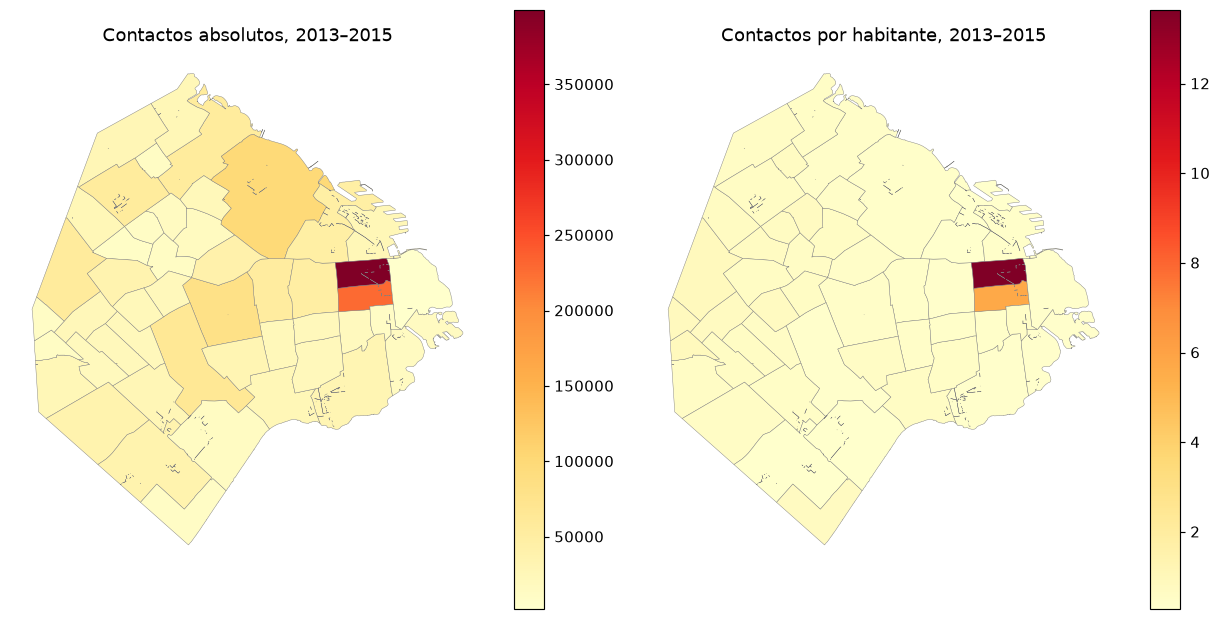

In [7]:
fig,axes=plt.subplots(1,2,figsize=(12,6))
for ax,column,title in zip(axes,['total','contactos_pc'],['Contactos absolutos, 2013–2015','Contactos por habitante, 2013–2015']):
    barrios_m.plot(ax=ax,column=column,cmap='YlOrRd',legend=True,linewidth=.3,edgecolor='gray')
    ax.set_axis_off(); ax.set_title(title)
plt.tight_layout(); plt.show()
rubros=(suaci_valido.groupby(['clave','RUBRO'],as_index=False).total.sum()
        .merge(barrios_m[['clave','POBLACION']],on='clave',validate='many_to_one'))
rubros['contactos_1k']=1000*rubros.total/rubros.POBLACION
rubros.to_csv(OUT/'tables/contactos_por_rubro_1k.csv',index=False)

### Preguntas de reflexión — Parte B
1. `contactos_pc = total / POBLACION`. Ajusta por población residente y evita confundir un barrio poblado con una mayor tasa. Se trata de **contactos acumulados de 2013–2015 por habitante**, no probabilidad, personas únicas ni tasa anual. Puede superar 1 porque hay múltiples contactos y población no residente que usa el centro.
2. Top 3: **SAN NICOLAS (13.643)**, **MONSERRAT (5.696)** y **VERSALLES (0.898)**. Los dos primeros corresponden al área central con actividad administrativa/comercial y mucha afluencia frente a una población residencial reducida. El tercero no permite generalizar esa misma explicación: hay que mirar rubros, denominador y calidad del registro antes de atribuir un patrón común a los tres.
3. La columna **RUBRO sí existe**; también existe `TIPO_PRESTACION`. Usaría contactos por RUBRO / población × 1000 y un período explícito. Se exporta esa segmentación. No equivale a incidencia de problemas ni mide quién pudo acceder al canal de atención.

## Parte C — Joins espaciales: SUBTE y cobertura
Se incluyen [líneas](https://bitsandbricks.github.io/data/subte_lineas.geojson) y [estaciones](https://bitsandbricks.github.io/data/subte_estaciones.geojson). Los conteos se refieren a registros de estación/línea de esa capa histórica, no necesariamente a complejos de intercambio o entradas físicas únicas.

In [8]:
lineas=gpd.read_file(DATA/'subte_lineas.geojson').to_crs(CRS_METRICO)
estaciones=gpd.read_file(DATA/'subte_estaciones.geojson').to_crs(CRS_METRICO).reset_index(drop=True)
estaciones['estacion_id']=np.arange(len(estaciones))
assert estaciones.geometry.geom_type.eq('Point').all() and estaciones.is_valid.all()
assert estaciones.estacion_id.is_unique
# Intersects incluye fronteras. Si hay varias asignaciones, se usa un desempate
# alfabético estable y se conserva el número de candidatos para auditarlo.
candidatos=gpd.sjoin(estaciones,barrios_m[['BARRIO','geometry']],how='left',predicate='intersects')
n_candidatos=candidatos.groupby('estacion_id').BARRIO.count()
asignadas=candidatos.sort_values(['estacion_id','BARRIO']).drop_duplicates('estacion_id').copy()
assert len(asignadas)==len(estaciones)
sin_asignar=asignadas.loc[asignadas.BARRIO.isna()]
print('Estaciones:',len(estaciones),'| candidatos múltiples:',int((n_candidatos>1).sum()),'| sin barrio:',len(sin_asignar))
assert sin_asignar.empty
estaciones['BARRIO']=estaciones.estacion_id.map(asignadas.set_index('estacion_id').BARRIO)
conteos=asignadas.groupby('BARRIO').size().rename('n_estaciones').reset_index()
barrios_m=barrios_m.merge(conteos,on='BARRIO',how='left',validate='one_to_one')
barrios_m['n_estaciones']=barrios_m.n_estaciones.fillna(0).astype(int)
barrios_m['estaciones_por_km2']=barrios_m.n_estaciones/(barrios_m.area_m2/1e6)
assert barrios_m.n_estaciones.sum()==len(estaciones)
asignadas.drop(columns='geometry').to_csv(OUT/'tables/asignacion_estaciones.csv',index=False)
barrios_m[['BARRIO','n_estaciones','estaciones_por_km2']].sort_values('estaciones_por_km2',ascending=False).head(12)

Estaciones: 86 | candidatos múltiples: 0 | sin barrio: 0


,BARRIO,n_estaciones,estaciones_por_km2
16,MONSERRAT,10,4.551732
31,SAN NICOLAS,9,3.932608
2,BALVANERA,11,2.534181
30,SAN CRISTOBAL,5,2.447662
11,CONSTITUCION,4,1.902948
27,RECOLETA,7,1.115762
1,ALMAGRO,4,0.988002
7,CABALLITO,6,0.876163
24,PARQUE PATRICIOS,3,0.801718
23,PARQUE CHAS,1,0.722286


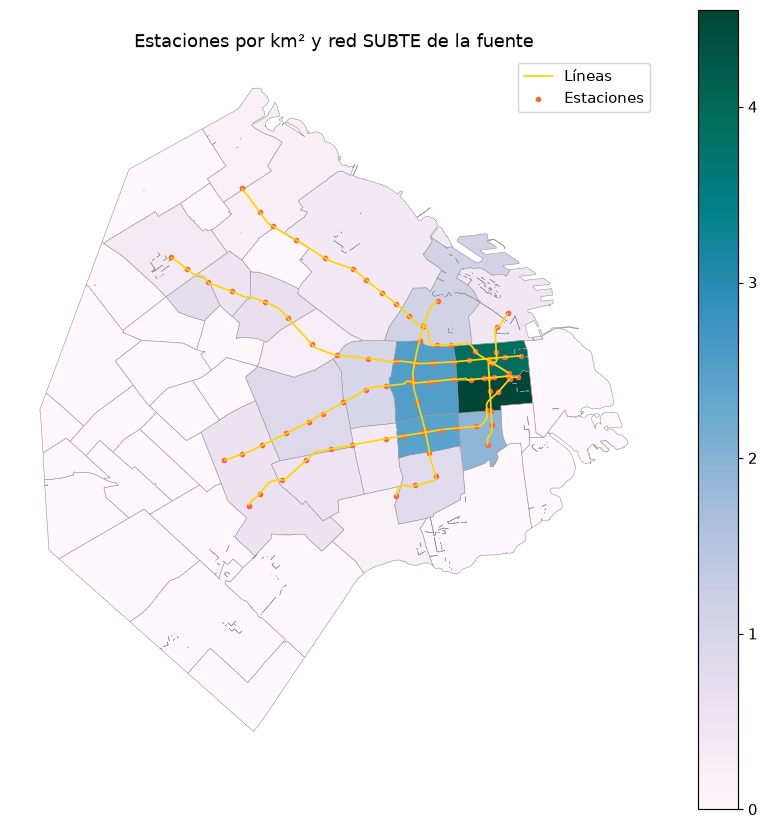

In [9]:
fig,ax=plt.subplots(figsize=(8,8))
barrios_m.plot(ax=ax,column='estaciones_por_km2',cmap='PuBuGn',legend=True,linewidth=.4,edgecolor='#999')
lineas.plot(ax=ax,color='gold',linewidth=1.2,label='Líneas')
estaciones.plot(ax=ax,color='tomato',markersize=8,label='Estaciones')
ax.set_axis_off(); ax.set_title('Estaciones por km² y red SUBTE de la fuente'); ax.legend()
plt.tight_layout(); plt.show()

### C.1 Nearest: barrio → estación más cercana
Se reproduce la aproximación de la consigna con centroides en metros. Una estación no atiende solo al barrio que contiene su punto. El centroide puede caer fuera de un barrio o en un lugar no transitable; se informa ese control y la distancia no representa a todos sus habitantes.

`sjoin_nearest` puede devolver varias filas en un empate. Se reduce a una por barrio mediante distancia y un identificador estable para evitar multiplicar polígonos en el merge.

In [10]:
centroides=barrios_m[['BARRIO','geometry']].copy()
centroides.geometry=centroides.centroid
centroides_fuera=int((~centroides.geometry.within(barrios_m.geometry)).sum())
nearest=gpd.sjoin_nearest(centroides,estaciones[['estacion_id','ESTACION','LINEA','geometry']],
                         how='left',distance_col='dist_min')
empates=int(nearest.BARRIO.duplicated().sum())
nearest=nearest.sort_values(['BARRIO','dist_min','estacion_id']).drop_duplicates('BARRIO')
barrios_m=barrios_m.merge(nearest[['BARRIO','dist_min','ESTACION']].rename(columns={'ESTACION':'estacion_cercana'}),
                         on='BARRIO',how='left',validate='one_to_one')
barrios_m['dist_min_m']=barrios_m.dist_min.astype(float)
assert len(barrios_m)==48 and barrios_m.dist_min_m.ge(0).all()
correlacion=float(barrios_m[['estaciones_por_km2','contactos_pc']].corr().iloc[0,1])
rho,p_spearman=spearmanr(barrios_m.estaciones_por_km2,barrios_m.contactos_pc)
peor=barrios_m.sort_values('dist_min_m',ascending=False).iloc[0]
barrios_m[['distancia_norm','densidad_norm']]=MinMaxScaler().fit_transform(barrios_m[['dist_min_m','densidad_hab_km2']])
ALPHA,BETA=.6,.4
barrios_m['score_prioridad']=ALPHA*barrios_m.distancia_norm+BETA*barrios_m.densidad_norm
print('Centroides fuera:',centroides_fuera,'| filas empatadas eliminadas:',empates)
print('Pearson estaciones/km² vs contactos_pc:',round(correlacion,4),'| Spearman:',round(rho,4))
print(barrios_m[['BARRIO','dist_min_m','estacion_cercana','score_prioridad']].sort_values('dist_min_m',ascending=False).head(8).round(2).to_string(index=False))

Centroides fuera: 0 | filas empatadas eliminadas: 0
Pearson estaciones/km² vs contactos_pc: 0.6821 | Spearman: -0.1964
         BARRIO  dist_min_m                     estacion_cercana  score_prioridad
VILLA RIACHUELO     5438.06    PLAZA DE LOS VIRREYES - EVA PERON             0.63
     VILLA REAL     5249.02                          SAN PEDRITO             0.69
      VERSALLES     4782.10                          SAN PEDRITO             0.64
        LINIERS     4726.46                          SAN PEDRITO             0.63
   VILLA DEVOTO     4030.88 JUAN MANUEL DE ROSAS - VILLA URQUIZA             0.56
      MATADEROS     4006.46    PLAZA DE LOS VIRREYES - EVA PERON             0.54
   VILLA LUGANO     3784.73    PLAZA DE LOS VIRREYES - EVA PERON             0.57
   MONTE CASTRO     3546.78                          SAN PEDRITO             0.54


### Preguntas de reflexión — Parte C
1. Esperaría una asociación positiva entre estaciones/km² y contactos per cápita si centralidad y afluencia elevan ambos; no es una ley. En estos datos Pearson=0.682 y Spearman=-0.196. Son asociaciones agregadas, sensibles a extremos, fechas y denominadores; no prueban que el SUBTE cause contactos ni describen comportamientos individuales.
2. El centroide más distante es **VILLA RIACHUELO, a 5,438 m** de PLAZA DE LOS VIRREYES - EVA PERON. La posición periférica respecto de la red incluida es una explicación plausible. No implica que todos sus habitantes estén a esa distancia ni que no tengan tren, premetro o colectivo: aquí se mide solo esta capa de SUBTE.
3. Se propone **score = 0,6 × distancia normalizada + 0,4 × densidad poblacional normalizada**, ambas con min–max entre barrios. Se prioriza el déficit de cercanía y luego la demanda residencial. Son pesos de escenario, no un óptimo aprendido. Contactos SUACI no se usa como demanda de viajes porque mide otro fenómeno; podría incorporarse como proxy únicamente con justificación y análisis de sensibilidad.

## Parte D — Interactivo con Folium
El mapa incluye coropleta, tooltip con población/contactos y capas separadas de líneas y estaciones. Los popups muestran nombre, línea y barrio. El HTML interactivo utiliza Leaflet y tiles externos: requiere conexión para cargar esas bibliotecas/tiles; los cálculos y mapas estáticos usan datos locales.

In [11]:
barrios_ll=barrios_m.to_crs(4326)
estaciones_ll=estaciones.to_crs(4326)
m=folium.Map(location=[-34.61,-58.44],tiles='CartoDB positron',zoom_start=11)
folium.Choropleth(geo_data=barrios_ll.__geo_interface__,data=barrios_m[['BARRIO','contactos_pc']],
    columns=['BARRIO','contactos_pc'],key_on='feature.properties.BARRIO',fill_color='YlOrRd',
    name='Contactos por habitante, 2013–2015',legend_name='Contactos acumulados por habitante').add_to(m)
folium.GeoJson(barrios_ll[['BARRIO','POBLACION','contactos_pc','n_estaciones','dist_min_m','geometry']],
    name='Información de barrios',style_function=lambda f:{'fillOpacity':0,'weight':.4,'color':'#555'},
    tooltip=folium.GeoJsonTooltip(fields=['BARRIO','POBLACION','contactos_pc','n_estaciones','dist_min_m'],
        aliases=['Barrio','Población','Contactos/hab','Estaciones','Distancia centroide (m)'],localize=True)).add_to(m)
fg_lineas=folium.FeatureGroup(name='Líneas SUBTE')
folium.GeoJson(lineas.to_crs(4326),style_function=lambda f:{'color':'#b58b00','weight':3}).add_to(fg_lineas)
fg_lineas.add_to(m)
fg_estaciones=folium.FeatureGroup(name='Estaciones SUBTE')
for row in estaciones_ll.itertuples():
    popup=f'<b>{html.escape(str(row.ESTACION))}</b><br>Línea: {html.escape(str(row.LINEA))}<br>Barrio: {html.escape(str(row.BARRIO))}<br>ID: {row.estacion_id}'
    folium.CircleMarker([row.geometry.y,row.geometry.x],radius=3,color='#be3030',fill=True,popup=popup).add_to(fg_estaciones)
fg_estaciones.add_to(m)
folium.LayerControl(collapsed=False).add_to(m)
m.save(OUT/'maps/mapa_caba_basico.html')
print('Mapa exportado:',OUT/'maps/mapa_caba_basico.html')
m

Mapa exportado: outputs\maps\mapa_caba_basico.html


### Preguntas de reflexión — Parte D
1. Usaría **FeatureGroup** para agrupar marcadores/líneas y **LayerControl** para encender o apagar capas; GeoJson y Choropleth también se registran como capas con nombre. Eso permite aislar cobertura, densidad y contactos sin mezclarlos visualmente.
2. **CartoDB.PositronNoLabels** ofrece un fondo claro con pocos elementos; Esri.WorldGrayCanvas es una alternativa de la consigna. El basemap no debe competir con el color de la coropleta. Se debe conservar la atribución y verificar condiciones/API del proveedor.
3. El popup implementado muestra **ESTACION, LINEA, BARRIO e ID**. En un producto real agregaría fecha de actualización, entradas accesibles y un enlace oficial; esos campos no se inventan si no existen en la capa.

## Extra 1 — Hexgrid y heatmaps comparables
Se genera una grilla hexagonal regular de **lado 350 m** con Shapely, sin depender de H3. La grilla se recorta al límite de CABA y usa el área efectiva de cada celda.

SUACI no trae coordenadas de contactos. Por eso **no es posible contar contactos observados por hexágono**. Se hace una estimación areal explícita: población uniforme dentro de cada radio y contactos distribuidos por población dentro de cada barrio. No se presentan esos valores como observaciones puntuales. El patrón de contactos/hab hereda las tasas de barrio; los hexágonos no crean evidencia más detallada.

Hexágonos: 715 | suma población estimada: 2890151.0002949666 | contactos estimados: 1995567.0001031368


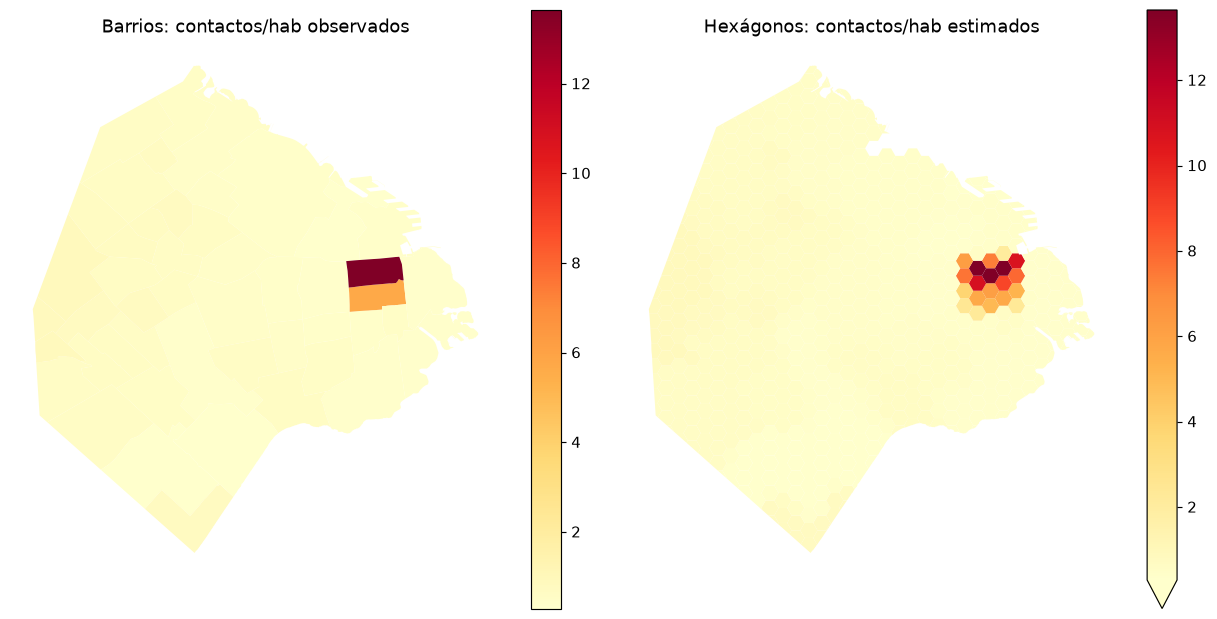

In [12]:
LADO_HEX=350.0
minx,miny,maxx,maxy=ciudad.bounds
hex_rows=[]
for col,x in enumerate(np.arange(minx-LADO_HEX,maxx+2*LADO_HEX,1.5*LADO_HEX)):
    y0=miny-np.sqrt(3)*LADO_HEX+(col%2)*np.sqrt(3)*LADO_HEX/2
    for y in np.arange(y0,maxy+2*LADO_HEX,np.sqrt(3)*LADO_HEX):
        coords=[(x+LADO_HEX*np.cos(a),y+LADO_HEX*np.sin(a)) for a in np.arange(6)*np.pi/3]
        polygon=Polygon(coords)
        if polygon.intersects(ciudad): hex_rows.append({'hex_id':len(hex_rows),'geometry':polygon})
hexgrid=gpd.GeoDataFrame(hex_rows,crs=CRS_METRICO).clip(gpd.GeoSeries([ciudad],crs=CRS_METRICO))
hexgrid=hexgrid.loc[hexgrid.area>1e-5].reset_index(drop=True)
hexgrid['hex_area_m2']=hexgrid.area
radio_hex=radios_m[['RADIO_ID','BARRIO','POBLACION','area_m2','geometry']].merge(
    barrios_m[['BARRIO','contactos_pc']],on='BARRIO',validate='many_to_one')
intersecciones=gpd.overlay(radio_hex,hexgrid[['hex_id','geometry']],how='intersection',keep_geom_type=True)
intersecciones['fraccion_area']=intersecciones.area/intersecciones.area_m2
intersecciones['poblacion_est']=intersecciones.POBLACION*intersecciones.fraccion_area
intersecciones['contactos_est']=intersecciones.poblacion_est*intersecciones.contactos_pc
hex_stats=intersecciones.groupby('hex_id')[['poblacion_est','contactos_est']].sum().reset_index()
hexgrid=hexgrid.merge(hex_stats,on='hex_id',how='left',validate='one_to_one')
hexgrid[['poblacion_est','contactos_est']]=hexgrid[['poblacion_est','contactos_est']].fillna(0)
hexgrid['contactos_pc_est']=hexgrid.contactos_est/hexgrid.poblacion_est.replace(0,np.nan)
hexgrid['contactos_km2_est']=hexgrid.contactos_est/(hexgrid.hex_area_m2/1e6)
hexgrid['percentil_contactos_km2']=hexgrid.contactos_km2_est.rank(pct=True)
assert np.isclose(hexgrid.poblacion_est.sum(),radios_m.POBLACION.sum(),rtol=1e-5)
assert np.isclose(hexgrid.contactos_est.sum(),barrios_m.total.sum(),rtol=1e-5)
assert abs(hexgrid.hex_area_m2.sum()-ciudad.area)/ciudad.area<1e-7
hexgrid.to_parquet(OUT/'layers/hexgrid.parquet',index=False)
hexgrid.drop(columns='geometry').to_csv(OUT/'tables/hexgrid_metricas.csv',index=False)
fig,axes=plt.subplots(1,2,figsize=(12,6))
barrios_m.plot(ax=axes[0],column='contactos_pc',cmap='YlOrRd',legend=True)
hexgrid.plot(ax=axes[1],column='contactos_pc_est',cmap='YlOrRd',legend=True,
             vmin=barrios_m.contactos_pc.min(),vmax=barrios_m.contactos_pc.max(),linewidth=0)
for ax,title in zip(axes,['Barrios: contactos/hab observados','Hexágonos: contactos/hab estimados']): ax.set_axis_off(); ax.set_title(title)
plt.tight_layout(); plt.show()
print('Hexágonos:',len(hexgrid),'| suma población estimada:',hexgrid.poblacion_est.sum(),'| contactos estimados:',hexgrid.contactos_est.sum())

**Interpretación:** la grilla regular facilita comparar áreas de tamaño parecido y ver cuánto depende un mapa de su zonificación (MAUP). Las celdas de borde tienen menos superficie y se normalizan por su área real. Los percentiles comparan posiciones relativas, no magnitudes absolutas. Tanto el cambio de lado como la posición de la grilla pueden cambiar el ranking; para sostener una decisión por hexágono harían falta datos geocodificados o un modelo de desagregación validado.

## Extra 2 — Redes y accesibilidad con OSMnx
Se usa una red real de OpenStreetMap. Los servicios Overpass no estaban disponibles para la descarga; se utilizó el [extracto público de BBBike para Buenos Aires](https://download.bbbike.org/osm/bbbike/BuenosAires/), se filtraron ways transitables a pie con pyosmium y se construyó el grafo con `OSMnx.graph_from_xml`. El XML filtrado, GraphML y script de preparación se incluyen.

El área de estudio cubre **Villa Riachuelo, Villa Lugano y Mataderos**, más las estaciones cercanas y un margen. Se comparan sus centroides con estaciones dentro del área de red; no se extrapola al resto de CABA ni se afirma que una ruta local sea el mínimo global fuera del recorte. La distancia de acceso/salida al nodo más cercano es un conector recto aproximado, no un sendero verificado.

Nodos: 19685 | aristas: 59404 | estaciones candidatas: 7
         BARRIO  alcanzable                      estacion_red  dist_euclid_global_m  dist_euclid_misma_estacion_m  dist_red_aprox_m  snap_origen_m  snap_destino_m  factor_red_euclid
      MATADEROS        True                       SAN PEDRITO               4006.46                       4248.78           4640.90          46.75            1.57               1.16
   VILLA LUGANO        True PLAZA DE LOS VIRREYES - EVA PERON               3784.73                       3784.73           4203.23           5.09           31.09               1.11
VILLA RIACHUELO        True PLAZA DE LOS VIRREYES - EVA PERON               5438.06                       5438.06           6648.99          51.86           31.09               1.22


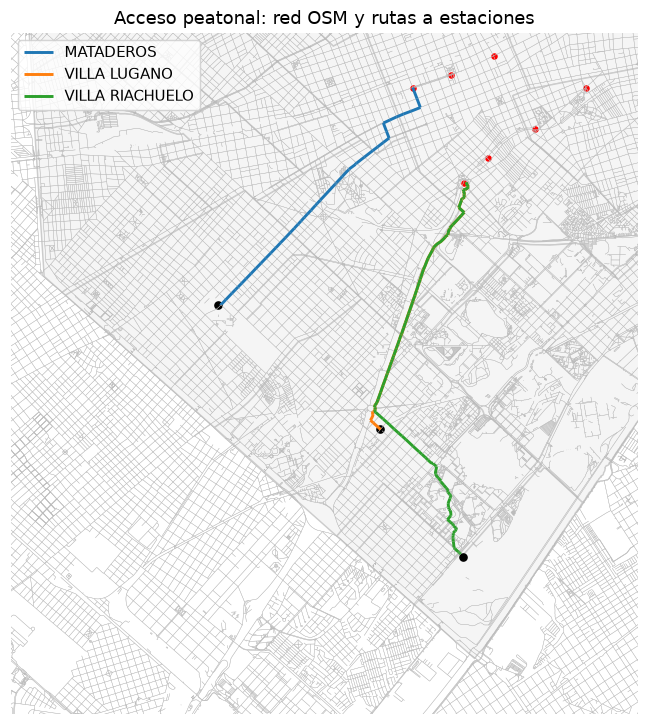

In [13]:
G=ox.load_graphml(DATA/'red_peatonal_sur.graphml')
Gp=ox.project_graph(G,to_crs=CRS_METRICO)
Gu=ox.convert.to_undirected(Gp)
assert len(Gu)>0 and Gu.number_of_edges()>0
assert all(float(d['length'])>=0 for _,_,d in Gu.edges(data=True))
area_red=gpd.read_file(DATA/'area_red.geojson').to_crs(CRS_METRICO).geometry.iloc[0]
estaciones_red=estaciones.loc[estaciones.intersects(area_red)].copy()
origenes=centroides.loc[centroides.BARRIO.isin(['VILLA RIACHUELO','VILLA LUGANO','MATADEROS'])].copy()
target_nodes,target_snaps=ox.distance.nearest_nodes(Gp,X=estaciones_red.geometry.x.to_numpy(),Y=estaciones_red.geometry.y.to_numpy(),return_dist=True)
estaciones_red['node']=target_nodes; estaciones_red['snap_m']=target_snaps
network_rows=[]; rutas=[]
for origen in origenes.itertuples():
    node_origin,snap_origin=ox.distance.nearest_nodes(Gp,X=origen.geometry.x,Y=origen.geometry.y,return_dist=True)
    distances,paths=nx.single_source_dijkstra(Gu,node_origin,weight='length')
    choices=[]
    for station in estaciones_red.itertuples():
        if station.node in distances:
            cost=float(snap_origin+distances[station.node]+station.snap_m)
            choices.append((cost,station.estacion_id,station))
    if not choices:
        network_rows.append({'BARRIO':origen.BARRIO,'alcanzable':False}); continue
    cost,_,station=min(choices,key=lambda c:(c[0],c[1]))
    euclid_same=float(origen.geometry.distance(station.geometry))
    global_euclid=float(barrios_m.set_index('BARRIO').loc[origen.BARRIO,'dist_min_m'])
    assert cost>=euclid_same*.995
    route=paths[station.node]
    for u,v in zip(route[:-1],route[1:]):
        edge=min(Gu.get_edge_data(u,v).values(),key=lambda d:d['length'])
        geom=edge.get('geometry',LineString([(Gp.nodes[u]['x'],Gp.nodes[u]['y']),(Gp.nodes[v]['x'],Gp.nodes[v]['y'])]))
        rutas.append({'BARRIO':origen.BARRIO,'geometry':geom})
    network_rows.append({'BARRIO':origen.BARRIO,'alcanzable':True,'estacion_red':station.ESTACION,
        'dist_euclid_global_m':global_euclid,'dist_euclid_misma_estacion_m':euclid_same,
        'dist_red_aprox_m':cost,'snap_origen_m':snap_origin,'snap_destino_m':station.snap_m,
        'factor_red_euclid':cost/global_euclid})
red_comparacion=pd.DataFrame(network_rows)
assert red_comparacion.alcanzable.all()
red_comparacion.to_csv(OUT/'tables/accesibilidad_red.csv',index=False)
rutas_gdf=gpd.GeoDataFrame(rutas,crs=CRS_METRICO)
rutas_gdf.to_parquet(OUT/'layers/rutas_peatonales.parquet',index=False)
print('Nodos:',len(G),'| aristas:',G.number_of_edges(),'| estaciones candidatas:',len(estaciones_red))
print(red_comparacion.round(2).to_string(index=False))
fig,ax=plt.subplots(figsize=(8,7))
barrios_m.plot(ax=ax,facecolor='#f5f5f5',edgecolor='#ccc')
nodes_gdf,edges_gdf=ox.graph_to_gdfs(Gp)
edges_gdf.plot(ax=ax,color='#bbb',linewidth=.25)
rutas_gdf.plot(ax=ax,column='BARRIO',linewidth=2,legend=True)
origenes.plot(ax=ax,color='black',markersize=24)
estaciones_red.plot(ax=ax,color='red',markersize=12)
ax.set_xlim(area_red.bounds[0],area_red.bounds[2]); ax.set_ylim(area_red.bounds[1],area_red.bounds[3])
ax.set_axis_off(); ax.set_title('Acceso peatonal: red OSM y rutas a estaciones')
plt.tight_layout(); plt.show()

**Resultado de la comparación:** los factores red / distancia recta van de 1.11 a 1.22. Calles, trazados y barreras obligan a rodeos; el centroide más lejano en línea recta no tiene por qué conservar la misma prioridad al medir por red. Los conectores de snap se informan por separado. No se incluyen tiempos de espera, transbordos, pendientes, horarios ni accesibilidad universal. Una ruta ausente por desconexión debe reportarse como no alcanzable, nunca como distancia cero.

## Extra 3 — Overlays y zonas excluidas
Se usan polígonos OSM etiquetados como parques, agua o uso industrial. La exclusión es un **escenario académico**, no una declaración de prohibición legal: un parque puede admitir una estación subterránea y un área industrial puede necesitar transporte. La viabilidad real exige normativa, servicios, riesgos y consulta local.

Se disuelven las restricciones para evitar contar superficies superpuestas más de una vez. Se calcula `difference` para superficie candidata e `intersection` para superficie excluida. Población y contactos siguen siendo totales del barrio: no se vuelven a sumar después de partir polígonos ni se reasignan a las piezas como si fueran observaciones nuevas.

Polígonos OSM: 1564 | área excluida (km²): 23.684494350566013
          BARRIO  frac_area_apta  dist_min_m  dist_candidato_m  score_recalculado
      VILLA REAL           0.968    5249.024          5213.162              0.673
       MATADEROS           0.936    4006.462          5060.091              0.638
       VERSALLES           0.968    4782.098          4839.243              0.629
 VILLA RIACHUELO           0.863    5438.061          5590.289              0.626
    VILLA DEVOTO           0.983    4030.884          4261.036              0.574
         LINIERS           0.978    4726.460          4284.940              0.572
    VILLA LUGANO           0.886    3784.729          3818.107              0.567
VILLA DEL PARQUE           0.992    2978.424          3087.418              0.521


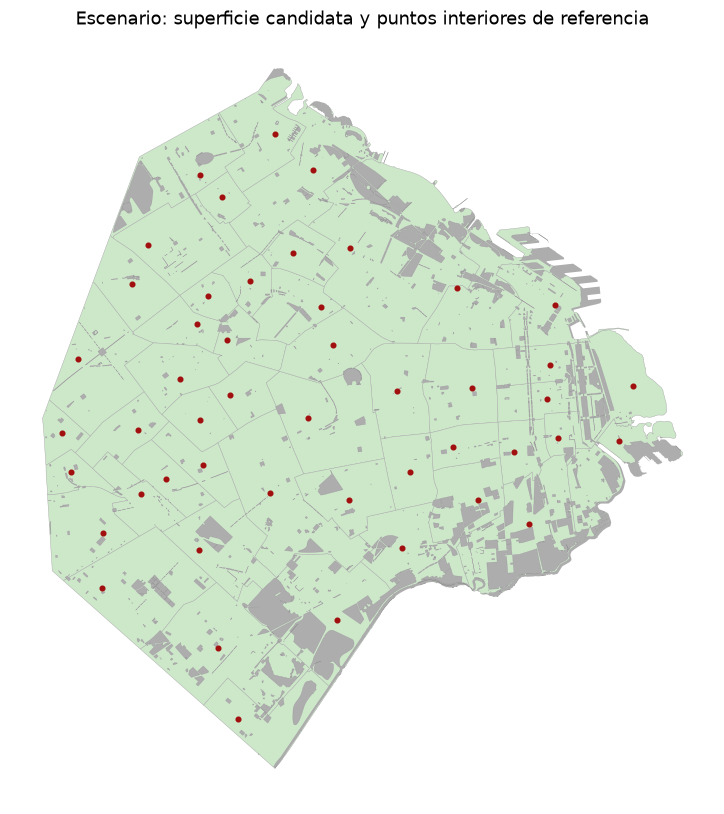

In [14]:
restricciones=gpd.read_parquet(DATA/'restricciones_osm.parquet').to_crs(CRS_METRICO)
restricciones.geometry=restricciones.geometry.make_valid()
restricciones=restricciones.loc[~restricciones.is_empty].copy()
assert restricciones.is_valid.all()
union_restricciones=restricciones.geometry.union_all()
mask=gpd.GeoDataFrame({'escenario':['parque/agua/industrial']},geometry=[union_restricciones],crs=CRS_METRICO)
campos=['BARRIO','POBLACION','total','area_m2','dist_min_m','score_prioridad','geometry']
permitidas=gpd.overlay(barrios_m[campos],mask,how='difference',keep_geom_type=True)
excluidas=gpd.overlay(barrios_m[['BARRIO','geometry']],mask,how='intersection',keep_geom_type=True)
permitidas['area_apta_m2']=permitidas.area
excluidas['area_excluida_m2']=excluidas.area
area_apta=permitidas.groupby('BARRIO').area_apta_m2.sum()
area_excluida=excluidas.groupby('BARRIO').area_excluida_m2.sum()
control_overlay=barrios_m[['BARRIO','area_m2']].set_index('BARRIO').copy()
control_overlay['area_geometria_m2']=barrios_m.set_index('BARRIO').geometry.area
control_overlay['diferencia_suma_radios_m2']=control_overlay.area_m2-control_overlay.area_geometria_m2
control_overlay['area_apta_m2']=area_apta.reindex(control_overlay.index,fill_value=0)
control_overlay['area_excluida_m2']=area_excluida.reindex(control_overlay.index,fill_value=0)
assert np.allclose(control_overlay.area_apta_m2+control_overlay.area_excluida_m2,control_overlay.area_geometria_m2,rtol=1e-8,atol=1)
assert not permitidas.BARRIO.duplicated().any()
assert (permitidas.set_index('BARRIO').POBLACION==barrios_m.set_index('BARRIO').loc[permitidas.BARRIO,'POBLACION']).all()
permitidas.to_parquet(OUT/'layers/zonas_candidatas.parquet',index=False)
control_overlay.to_csv(OUT/'tables/control_overlay.csv')
candidatos=[]
for row in permitidas.itertuples():
    point=row.geometry.representative_point()
    distance=float(estaciones.geometry.distance(point).min())
    candidatos.append({'BARRIO':row.BARRIO,'geometry':point,'dist_candidato_m':distance,'area_apta_m2':row.area_apta_m2})
candidatos=gpd.GeoDataFrame(candidatos,crs=CRS_METRICO).merge(
    barrios_m[['BARRIO','POBLACION','dist_min_m','score_prioridad','densidad_norm']],on='BARRIO',validate='one_to_one')
candidatos['frac_area_apta']=candidatos.area_apta_m2/candidatos.BARRIO.map(barrios_m.set_index('BARRIO').area_m2)
candidatos['dist_candidato_norm']=MinMaxScaler().fit_transform(candidatos[['dist_candidato_m']])
candidatos['score_recalculado']=.6*candidatos.dist_candidato_norm+.4*candidatos.densidad_norm
assert candidatos.geometry.within(permitidas.set_index('BARRIO').loc[candidatos.BARRIO].set_axis(candidatos.index).geometry).all()
candidatos_ll=candidatos.to_crs(4326)
candidatos['lon']=candidatos_ll.geometry.x; candidatos['lat']=candidatos_ll.geometry.y
candidatos.drop(columns='geometry').sort_values('score_recalculado',ascending=False).to_csv(OUT/'tables/prioridad_tras_overlay.csv',index=False)
propuesta=candidatos.set_index('BARRIO').loc[peor.BARRIO]
fig,ax=plt.subplots(figsize=(8,8))
permitidas.plot(ax=ax,color='#cce8c9',edgecolor='#aaa',linewidth=.3)
mask.plot(ax=ax,color='#8b8b8b',alpha=.7)
candidatos.plot(ax=ax,color='#a10f0f',markersize=10)
ax.set_axis_off(); ax.set_title('Escenario: superficie candidata y puntos interiores de referencia')
plt.tight_layout(); plt.show()
print('Polígonos OSM:',len(restricciones),'| área excluida (km²):',union_restricciones.area/1e6)
print(candidatos[['BARRIO','frac_area_apta','dist_min_m','dist_candidato_m','score_recalculado']].sort_values('score_recalculado',ascending=False).head(8).round(3).to_string(index=False))

**Interpretación del overlay:** la superficie considerada candidata conserva el 88.38% del área de barrios. Los puntos se eligen con `representative_point` sobre la geometría restante, para asegurar pertenencia; no son emplazamientos optimizados. El cambio entre centroide y punto interior altera la distancia y el ranking. La población residente original no se conoce por pieza excluida: no se afirma que toda ella viva en la superficie restante ni se interpreta población/área apta como una nueva densidad observada.

## Extra 4 — Visualización avanzada interactiva
Se agrega al mapa una capa hexagonal estimada, densidad de estaciones, restricciones y puntos de referencia. Las leyendas explicitan qué valores son observados y cuáles estimados. Se exporta HTML y una guía de uso. “Publicar” aquí se implementa como artefacto HTML listo para abrir/compartir, sin crear una cuenta ni un alojamiento externo.

In [15]:
advanced=folium.Map(location=[-34.61,-58.44],tiles='CartoDB positron',zoom_start=11)
folium.TileLayer('OpenStreetMap',name='OpenStreetMap',show=False).add_to(advanced)
folium.Choropleth(geo_data=barrios_ll.__geo_interface__,data=barrios_m[['BARRIO','contactos_pc']],columns=['BARRIO','contactos_pc'],
    key_on='feature.properties.BARRIO',name='Contactos/hab observados (barrios)',fill_color='YlOrRd',
    legend_name='Contactos/hab acumulados 2013–2015').add_to(advanced)
import branca.colormap as cm
hex_colors=cm.linear.YlOrRd_09.scale(0,1)
hex_geo=hexgrid.to_crs(4326)
folium.GeoJson(hex_geo[['hex_id','poblacion_est','contactos_est','contactos_pc_est','percentil_contactos_km2','geometry']],
    name='Hexágonos ESTIMADOS: percentil contactos/km²',show=False,
    style_function=lambda f:{'fillColor':hex_colors(f['properties']['percentil_contactos_km2']),'color':'#aaa','weight':.2,'fillOpacity':.7},
    tooltip=folium.GeoJsonTooltip(fields=['hex_id','poblacion_est','contactos_est','contactos_pc_est'],
        aliases=['Hexágono','Población estimada','Contactos estimados','Contactos/hab estimados'],localize=True)).add_to(advanced)
hex_colors.caption='Percentil contactos/km² estimados (0–1); activar capa hexagonal'; hex_colors.add_to(advanced)
folium.GeoJson(barrios_ll[['BARRIO','n_estaciones','estaciones_por_km2','dist_min_m','geometry']],
    name='Cobertura: estaciones/km²',show=False,
    style_function=lambda f:{'fillColor':cm.linear.PuBuGn_09.scale(0,float(barrios_m.estaciones_por_km2.max()))(f['properties']['estaciones_por_km2']),
                             'weight':.5,'color':'gray','fillOpacity':.65},
    tooltip=folium.GeoJsonTooltip(fields=['BARRIO','n_estaciones','estaciones_por_km2','dist_min_m'],localize=True)).add_to(advanced)
folium.GeoJson(lineas.to_crs(4326),name='Líneas SUBTE',style_function=lambda f:{'color':'#1a4080','weight':2}).add_to(advanced)
station_layer=folium.FeatureGroup(name='Estaciones: nombre/línea/barrio')
for row in estaciones_ll.itertuples():
    folium.CircleMarker([row.geometry.y,row.geometry.x],radius=3,color='red',fill=True,
        popup=f'{html.escape(str(row.ESTACION))}<br>Línea {html.escape(str(row.LINEA))}<br>{html.escape(str(row.BARRIO))}').add_to(station_layer)
station_layer.add_to(advanced)
folium.GeoJson(restricciones.to_crs(4326),name='Escenario de exclusión: OSM',show=False,
    style_function=lambda f:{'color':'#555','weight':.5,'fillColor':'#777','fillOpacity':.5}).add_to(advanced)
point_layer=folium.FeatureGroup(name='Puntos interiores: referencias para evaluar',show=False)
for row in candidatos.to_crs(4326).itertuples():
    folium.CircleMarker([row.geometry.y,row.geometry.x],radius=4,color='purple',fill=True,
        popup=f'{html.escape(row.BARRIO)}<br>Score escenario: {row.score_recalculado:.3f}<br>No es un emplazamiento aprobado').add_to(point_layer)
point_layer.add_to(advanced)
folium.LayerControl(collapsed=False).add_to(advanced)
advanced.save(OUT/'maps/mapa_caba_avanzado.html')
guia="""Abrir mapa_caba_avanzado.html en un navegador con conexión a Internet.
Usar el selector de capas de la esquina superior derecha. Comparar una coropleta por vez para evitar mezcla de colores.
La coropleta inicial muestra contactos SUACI 2013–2015 por habitante; no personas únicas ni demanda de transporte.
Los hexágonos muestran estimaciones y percentiles de contactos/km², no contactos geocodificados observados.
La cobertura usa una capa histórica de estaciones; clic en puntos para ver nombre, línea y barrio.
Las exclusiones son un escenario de estudio, no prohibiciones legales. Los puntos violetas son referencias interiores, no estaciones propuestas definitivamente.
Las leyendas son fijas: leer la correspondiente a la capa activa. Los mapas estáticos se incluyen para consulta sin tiles externos.
Fuentes y fechas: data/fuentes.json y data/fuentes_extras.json. Atribución OSM/CARTO visible en el mapa.
"""
(OUT/'maps/GUIA_DEL_MAPA.txt').write_text(guia,encoding='utf-8')
print('Mapa avanzado y guía exportados.')

Mapa avanzado y guía exportados.


## Extra 5 — IO y performance
Se compara la misma capa en GeoJSON y GeoParquet, con pyogrio para IO vectorial y pyarrow para Parquet. También se simplifica con tolerancia de 10 m en el CRS métrico. Son tiempos locales con cache del sistema operativo, no una comparación universal ni una prueba de lectura en frío.

La simplificación se limita a una copia de visualización: las métricas oficiales y los joins anteriores usan la geometría original. Preservar topología por polígono no garantiza preservar fronteras compartidas entre radios.

Radios que conservan geometría original por QA de simplificación: 1
                     format   bytes  write_s  median_read_s  vertices
           GeoJSON original 4540068   0.1965         0.1249     60755
        GeoParquet original  645690   0.0193         0.0177     60755
GeoParquet simplificado 10m  340097   0.0175         0.0154     22785
Error relativo de área por simplificación — mediana/p95/máximo: {0.5: 0.002202024318751044, 0.95: 0.024408509832426335, 1.0: 0.29364361736293626}
Cambio relativo área total: -0.0003660496180392103


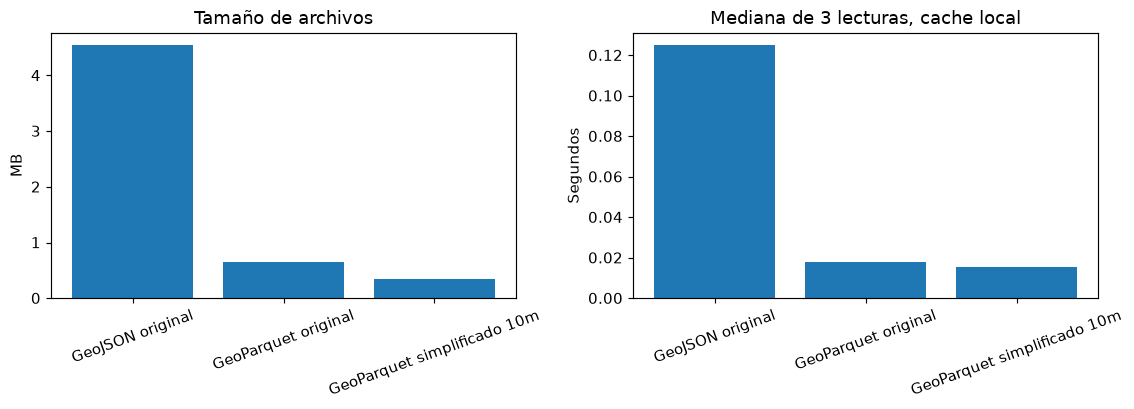

In [16]:
radios_parquet=OUT/'layers/radios_originales.parquet'
radios_simplificados=radios_m.copy()
radios_simplificados.geometry=radios_simplificados.geometry.simplify(10,preserve_topology=True)
fallos_simplificacion=(~radios_simplificados.is_valid)|radios_simplificados.is_empty
# Una simplificación local puede invalidar la relación entre partes de un
# MultiPolygon. En esos casos se conserva la geometría original sin alterarla.
radios_simplificados.loc[fallos_simplificacion,'geometry']=radios_m.loc[fallos_simplificacion,'geometry']
radios_simplificados['area_simplificada_m2']=radios_simplificados.area
assert radios_simplificados.is_valid.all() and not radios_simplificados.is_empty.any()
print('Radios que conservan geometría original por QA de simplificación:',int(fallos_simplificacion.sum()))
rows_io=[]
for label,frame,destination,kind in [
    ('GeoJSON original',radios_m,OUT/'layers/radios_originales.geojson','geojson'),
    ('GeoParquet original',radios_m,radios_parquet,'parquet'),
    ('GeoParquet simplificado 10m',radios_simplificados,OUT/'layers/radios_simplificados_10m.parquet','parquet')]:
    start=time.perf_counter()
    if kind=='geojson': frame.to_file(destination,driver='GeoJSON',engine='pyogrio')
    else: frame.to_parquet(destination,index=False,compression='zstd')
    write_seconds=time.perf_counter()-start
    read_times=[]
    for _ in range(3):
        start=time.perf_counter()
        recovered=gpd.read_file(destination,engine='pyogrio') if kind=='geojson' else gpd.read_parquet(destination)
        read_times.append(time.perf_counter()-start)
    assert len(recovered)==len(frame) and recovered.crs==frame.crs
    assert recovered.RADIO_ID.tolist()==frame.RADIO_ID.tolist()
    assert np.allclose(recovered.POBLACION,frame.POBLACION)
    assert np.allclose(recovered.area,frame.area,rtol=1e-8,atol=1e-3)
    rows_io.append({'format':label,'bytes':destination.stat().st_size,'write_s':write_seconds,
                    'median_read_s':float(np.median(read_times)),'vertices':int(shapely.get_num_coordinates(frame.geometry.to_numpy()).sum())})
io_metrics=pd.DataFrame(rows_io)
relative_area_error=(radios_simplificados.area-radios_m.area).abs()/radios_m.area
print(io_metrics.round(4).to_string(index=False))
print('Error relativo de área por simplificación — mediana/p95/máximo:',relative_area_error.quantile([.5,.95,1]).to_dict())
print('Cambio relativo área total:',(radios_simplificados.area.sum()/radios_m.area.sum()-1))
io_metrics.to_csv(OUT/'tables/io_performance.csv',index=False)
fig,axes=plt.subplots(1,2,figsize=(11,4))
axes[0].bar(io_metrics['format'],io_metrics.bytes/1e6); axes[0].set_ylabel('MB'); axes[0].set_title('Tamaño de archivos')
axes[1].bar(io_metrics['format'],io_metrics.median_read_s); axes[1].set_ylabel('Segundos'); axes[1].set_title('Mediana de 3 lecturas, cache local')
for ax in axes: ax.tick_params(axis='x',rotation=20)
plt.tight_layout(); plt.show()

**Trade-offs:** GeoParquet original ocupa 14.2% del GeoJSON equivalente en esta ejecución y conserva geometría, CRS y atributos verificados. La simplificación reduce vértices de 60755 a 22785, pero el error relativo de área alcanza 29.36% en el peor radio. No se acepta automáticamente para análisis por ser más liviana; la tolerancia debe evaluarse según el tamaño de las unidades y la tarea. Para grandes volúmenes, GeoJSON es verboso y costoso de parsear; GeoParquet facilita columnas y compresión, mientras que GeoJSON mantiene interoperabilidad web.

## Reflexiones finales
1. Usar **EPSG:32721** puso las coordenadas del análisis en **metros**, las áreas en m² y las distancias en m. Evitó tratar grados como longitudes y áreas en grados² como superficies físicas; 3857 se usó solo para tiles, por su distorsión en la latitud de CABA.
2. Normalizar por km² y por habitante evita que el mapa muestre solo tamaño de superficie o población. `contactos_pc` cambió especialmente la lectura de **SAN NICOLAS**: su actividad central y denominador residencial pequeño elevan el valor. No es una medida directa de bienestar ni de necesidad de transporte y acumula tres años.
3. La peor cobertura del centroide en la capa SUBTE es **VILLA RIACHUELO**. Como punto de referencia para estudiar factibilidad después de excluir el escenario de parques/agua/industria, se obtiene aproximadamente **latitud -34.69295, longitud -58.47224**. Se evalúan distancia de acceso, densidad, conectividad de red, usos del suelo y otras modalidades. El punto no es una localización optimizada ni una autorización para construir; el ranking puede priorizar otro barrio si se cambian los pesos o la métrica.
4. Limitaciones: **GeoJSON** para capas grandes y **Latin-1 con mojibake** en SUACI. Mitigaciones implementadas: GeoParquet/pyogrio y simplificación solo para visualización; reparación documentada de texto, clave normalizada y auditoría de registros sin barrio. Se suman fecha desigual entre fuentes, centroides como aproximación, recorte de la red, conectores de snap y desagregación hexagonal estimada.
5. Checklist: **[x] CRS**, **[x] geometrías válidas**, **[x] índices espaciales**, **[x] tests de conteos/áreas**, **[x] documentación de fuentes y condiciones conocidas**. Los siguientes checks reproducen las conservaciones y exportan una ficha de calidad. Cuando una fuente no declara licencia en el archivo, no se inventa: se deja el enlace de origen para verificar condiciones antes de redistribuirla públicamente.

In [17]:
# Validaciones finales y exportación de resultados.
assert radios_m.crs==barrios_m.crs==estaciones.crs==lineas.crs
assert radios_m.is_valid.all() and barrios_m.is_valid.all()
assert radios_m.sindex is not None and estaciones.sindex is not None
assert barrios_m.BARRIO.is_unique and len(barrios_m)==48
assert barrios_m.n_estaciones.sum()==len(estaciones)==86
assert np.isclose(barrios_m.POBLACION.sum(),radios.POBLACION.sum())
assert np.isclose(hexgrid.contactos_est.sum(),suaci_valido.total.sum(),rtol=1e-5)
assert np.isclose(barrios_m.total.sum()+sin_barrio.total.sum(),suaci.total.sum())
assert np.isfinite(barrios_m[['area_m2','contactos_pc','estaciones_por_km2','dist_min_m','score_prioridad']]).all().all()
barrios_m.drop(columns='geometry').to_csv(OUT/'tables/barrios_metricas.csv',index=False)
barrios_m.to_parquet(OUT/'layers/barrios_metricas.parquet',index=False)
estaciones.to_parquet(OUT/'layers/estaciones_asignadas.parquet',index=False)
packages=['geopandas','shapely','pyproj','contextily','folium','mapclassify','osmnx','pyarrow','numpy','pandas','matplotlib','scipy','networkx','osmium']
versions={name:version(name) for name in packages}
Path('requirements.txt').write_text(''.join(f'{name}=={installed}'+chr(10) for name,installed in versions.items()),encoding='utf-8')
qa={'crs_analysis':CRS_METRICO,'radios':len(radios),'barrios':len(barrios_m),'estaciones':len(estaciones),
    'invalid_source_geometries':invalidas_entrada,'suaci_period_min':int(suaci.PERIODO.min()),'suaci_period_max':int(suaci.PERIODO.max()),
    'suaci_contacts_unassigned':int(sin_barrio.total.sum()),'hex_cells':len(hexgrid),'network_comparison_neighborhoods':len(red_comparacion),
    'osm_exclusion_polygons':len(restricciones),'all_checks_passed':True,'versions':versions}
(OUT/'tables/calidad_pipeline.json').write_text(json.dumps(qa,indent=2),encoding='utf-8')
print(json.dumps(qa,indent=2,ensure_ascii=False))

{
  "crs_analysis": "EPSG:32721",
  "radios": 3554,
  "barrios": 48,
  "estaciones": 86,
  "invalid_source_geometries": 0,
  "suaci_period_min": 201301,
  "suaci_period_max": 201512,
  "suaci_contacts_unassigned": 5777,
  "hex_cells": 715,
  "network_comparison_neighborhoods": 3,
  "osm_exclusion_polygons": 1564,
  "all_checks_passed": true,
  "versions": {
    "geopandas": "1.2.0",
    "shapely": "2.2.0",
    "pyproj": "3.8.0",
    "contextily": "1.7.1",
    "folium": "0.20.0",
    "mapclassify": "2.11.0",
    "osmnx": "2.1.1",
    "pyarrow": "26.0.0",
    "numpy": "2.5.3",
    "pandas": "3.0.6",
    "matplotlib": "3.11.2",
    "scipy": "1.18.1",
    "networkx": "3.6.1",
    "osmium": "4.3.2"
  }
}


## Fuentes y referencias
- [Consigna y lecturas sugeridas](https://juanfkurucz.com/ucu-id/ut4/12-geoespacial/).
- [Radios censales CABA](https://bitsandbricks.github.io/data/CABA_rc.geojson), [SUACI](https://bitsandbricks.github.io/data/gcba_suaci_comunas.csv), [líneas](https://bitsandbricks.github.io/data/subte_lineas.geojson) y [estaciones](https://bitsandbricks.github.io/data/subte_estaciones.geojson). Copias locales y hashes en `data/fuentes.json`.
- [Extractos BBBike de Buenos Aires](https://download.bbbike.org/osm/bbbike/BuenosAires/) y [licencia/atribución de OpenStreetMap](https://www.openstreetmap.org/copyright). OSM se distribuye bajo ODbL; fecha y hash del extracto en `data/fuentes_extras.json`.
- [GeoPandas: CRS](https://geopandas.org/en/stable/docs/user_guide/projections.html), [joins](https://geopandas.org/en/stable/docs/user_guide/mergingdata.html), [overlays](https://geopandas.org/en/stable/docs/user_guide/set_operations.html) y [IO](https://geopandas.org/en/stable/docs/user_guide/io.html).
- [OSMnx](https://osmnx.readthedocs.io/en/stable/), [pyosmium](https://docs.osmcode.org/pyosmium/latest/), [Folium](https://python-visualization.github.io/folium/latest/) y [Contextily](https://contextily.readthedocs.io/en/latest/).